# Exercise 2 - Chapter 2
**Julian Barth**
## Emulsion Polymerisation

## 1) 
### Preliminary calculation of seed mass and number

Monomer & Initiator Mass:
$$m_M = M_0 \cdot V_{sus} \cdot M_{m,M}$$
$$m_I = w_{I,0} \cdot m_M$$

The total mass of the system is $m_{tot} = \frac{m_{pol}}{w_{Pol,seeds}}$. 
so the mass of water is:
   $$m_w = m_{pol} \left( \frac{1}{w_{Pol,seeds}} - 1 \right) - m_M - m_I$$


The total volume is constant (and initiator volume negligeable as we don't have data on it).
   $$V_{sus} = \frac{m_w}{\rho_{water}} + \frac{m_{pol}}{\rho_{Pol}} + \frac{m_M}{\rho_M}$$
   
   We can thus substitute m_w $m_w$ and isolate $m_{pol}$
Seed Count:  
    ($N_p$).$$N_p = \frac{m_{pol}}{\frac{\pi}{6} (d_{Pol,seeds}^0)^3 \cdot \rho_{Pol}}$$


In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
%config InlineBackend.figure_format = 'retina'

# Constants
V_sus = 10.0          # L
d0_pol = 50e-9        # m
M0_conc = 2.0         # mol/L (relative to suspension volume)
w_I0 = 0.01           # mass fraction initiator wrt monomer
w_pol_seeds = 0.05    # weight fraction of unswollen seeds wrt entire mixture

M_mM = 100.0          # g/mol
M_mI = 164.0          # g/mol
phi_M_star = 0.5      # volume fraction of monomer in particles
rho_pol = 1.10        # kg/L
rho_M = 0.94          # kg/L
rho_w = 1.00          # kg/L

kp = 715.0            # L/(mol s)
N_A = 6.022e23        # 1/mol
cmc = 40e-3           # mol/L
a_E = 50e-20          # m^2 (50 Angstrom^2)
K_E = 100.0           # L/mol

# Initial System Balances
# Monomer and Initiator added
m_M = M0_conc * V_sus * (M_mM / 1000.0)  # kg 
m_I = w_I0 * m_M                         # kg

# Solving the system algebraically for m_pol and m_w:

term_num = V_sus + (m_M + m_I) / rho_w - (m_M / rho_M)
term_den = ((1.0 / w_pol_seeds) - 1.0) / rho_w + (1.0 / rho_pol)
m_pol = term_num / term_den

m_w = m_pol * ((1.0 / w_pol_seeds) - 1.0) - m_M - m_I
m_tot = m_w + m_pol + m_M + m_I

# Seed particle characteristics
v_p0 = (np.pi / 6.0) * (d0_pol * 10.0) ** 3  # L (converting m to dm/L)
m_p0 = v_p0 * rho_pol                        # kg
N_p = m_pol / m_p0                           # Total number of particles
N_p_vol = N_p / V_sus                        # Particles per L of suspension

print(f"Total Mass: {m_tot:.2f} kg, Water Mass: {m_w:.2f} kg, Polymer Mass: {m_pol:.3f} kg")
print(f"Total Number of Seed Particles (N_p): {N_p:.3e}")

Total Mass: 9.94 kg, Water Mass: 7.42 kg, Polymer Mass: 0.497 kg
Total Number of Seed Particles (N_p): 6.902e+18


### a) maximum emulsifier concentration

Total Seed Surface Area per Volume:
$$a_p = \frac{N_p \cdot \pi (d_{Pol,seeds}^0)^2}{V_{sus}}$$

Saturation & Langmuir 

   $$\Gamma_E^\infty = \frac{a_p}{a_E \cdot N_A}$$
   $$\Gamma_E = \Gamma_E^\infty \frac{K_E \cdot E_w}{1 + K_E \cdot E_w}$$
   
   Maximum Total Emulsifier:
   $$E_{0,max} = E_w + \Gamma_E$$

In [5]:
# To avoid secondary nucleation, the free emulsifier must not exceed the CMC.
E_w = cmc

# Surface area of a single seed particle (s_p)
s_p = np.pi * (d0_pol)**2  # m^2

# Surface area of the particles per unit volume (a_p)
a_p = (N_p * s_p) / V_sus  # m^2 / L

# Saturation concentration of adsorbed emulsifier (Eq 2.9)
Gamma_E_inf = a_p / (a_E * N_A)  # mol / L

# Adsorbed emulsifier concentration using Langmuir isotherm (Eq 2.8)
Gamma_E = Gamma_E_inf * ((K_E * E_w) / (1 + K_E * E_w))  # mol / L

# In the mass balance E_0 = E_w + E_p + E_M (with E_M negligible), 
# E_p is the adsorbed concentration (Gamma_E).
E_p = Gamma_E
E_0 = E_w + E_p

print(f"Q1a: Maximum total emulsifier concentration (E_0) = {E_0:.4f} mol/L")

Q1a: Maximum total emulsifier concentration (E_0) = 0.0544 mol/L


The calculated maximum total emulsifier ($E_0 \approx 0.0544$ mol/L) exceeds the CMC ($0.040$ mol/L). This is physically consistent because the CMC solely dictates the upper limit of the *free* aqueous emulsifier concentration ($E_w$). A substantial portion of the total added emulsifier ($E_p \approx 0.0144$ mol/L) adsorbs onto the large surface area of the existing polymer. Micelle formation, and thus secondary nucleation, will only occur if $E_0$ exceeds the sum of this saturation adsorption and the CMC.

### b) Largest Particle Size

The particles swell to their absolute maximum volume at the exact instant the monomer droplets are depleted (the end of Interval II). At this point, the volume fraction of monomer in the particles is still $\phi_M^* = 0.5$, meaning the volume of the polymer equals the volume of the unreacted monomer.   Conversion at Depletion ($X_{dep}$): Equate the physical volumes and solve for $X_{dep}$.$$\frac{m_{pol} + X_{dep} \cdot m_M}{\rho_{Pol}} = \frac{(1 - X_{dep}) \cdot m_M}{\rho_M}$$Maximum Diameter: Calculate the total swollen volume of a single particle at $X_{dep}$ and back out the diameter.$$d_{max} = \left( \frac{6 \cdot (V_{pol} + V_{monomer})}{N_p \cdot \pi} \right)^{1/3}$$

In [9]:
# The swollen particle reaches its maximum volume precisely when the monomer droplets are fully depleted.
# At this point, all remaining monomer is inside the particles, and phi = 0.5.
# Volume of polymer = Volume of monomer

# V_pol = (m_pol + X * m_M) / rho_pol
# V_mon = ((1 - X) * m_M) / rho_M
# Equating V_pol and V_mon to find conversion X at depletion:
# (m_pol + X * m_M)/rho_pl = ((1 - X) * m_M)/rho_m

def find_depletion_conversion():
    # Solving A + B*X = C - C*X -> X(B + C) = C - A
    A = m_pol / rho_pol
    B = m_M / rho_pol
    C = m_M / rho_M
    return (C - A) / (B + C)

X_depletion = find_depletion_conversion()

# Volumes at depletion
V_pol_max = (m_pol + X_depletion * m_M) / rho_pol
V_mon_max = ((1 - X_depletion) * m_M) / rho_M
V_p_tot_max = V_pol_max + V_mon_max  # Total swollen volume

v_p_max = V_p_tot_max / N_p  # Volume of a single swollen particle in L
d_max_dm = ( (6 * v_p_max) / np.pi ) ** (1/3) # dm
d_max_nm = d_max_dm * 1e8 # converting dm to nm

print(f"Conversion at droplet depletion: {X_depletion:.3f}")
print(f"Q1b: Largest particle diameter during reaction = {d_max_nm:.2f} nm")

Conversion at droplet depletion: 0.425
Q1b: Largest particle diameter during reaction = 87.82 nm


### c) minimum emulsifier concentration
The system is most vulnerable to coagulation when the particles are at their largest ($d_{max}$). You need 20% coverage ($\frac{\Gamma_E}{\Gamma_E^\infty} = 0.2$) exactly at this point.   Required Aqueous Concentration: Rearrange the Langmuir isotherm to find the $E_{w,min}$ required to maintain 20% coverage.$$0.2 = \frac{K_E \cdot E_{w,min}}{1 + K_E \cdot E_{w,min}}$$Minimum Total Emulsifier: Recalculate $a_p$ and $\Gamma_E^\infty$ using $d_{max}$, then sum the components.$$\Gamma_{E,min} = 0.2 \cdot \Gamma_{E,max}^\infty$$$$E_{0,min} = E_{w,min} + \Gamma_{E,min}$$

In [12]:
# Minimum required coverage is Gamma_E / Gamma_inf = 0.2
theta_min = 0.2

# Find required E_w for this coverage using Langmuir
# 0.2 = (K_E * E_w) / (1 + K_E * E_w) -> E_w = 0.2 / (0.8 * K_E)
E_w_min = theta_min / ((1 - theta_min) * K_E)

# Calculate saturation adsorption at the maximum particle size
S_tot_max = N_p * np.pi * (d_max_nm * 1e-9)**2
n_E_inf_max = S_tot_max / (a_E * N_A)
Gamma_inf_max = n_E_inf_max / V_sus

E_p_min = theta_min * Gamma_inf_max
E_0_min = E_w_min + E_p_min

print(f"Q1c: Minimum total emulsifier concentration (E_0_min) = {E_0_min:.4f} mol/L")

Q1c: Minimum total emulsifier concentration (E_0_min) = 0.0136 mol/L


The minimum emulsifier required must be calculated at the point of maximum surface area (Interval II/III transition) to ensure the particles remain stable throughout the entire reaction lifecycle. The Langmuir isotherm algebraically dictates the exact aqueous equilibrium concentration necessary to sustain 20% surface coverage.

## 2) Kinetics Simulation & Plotting

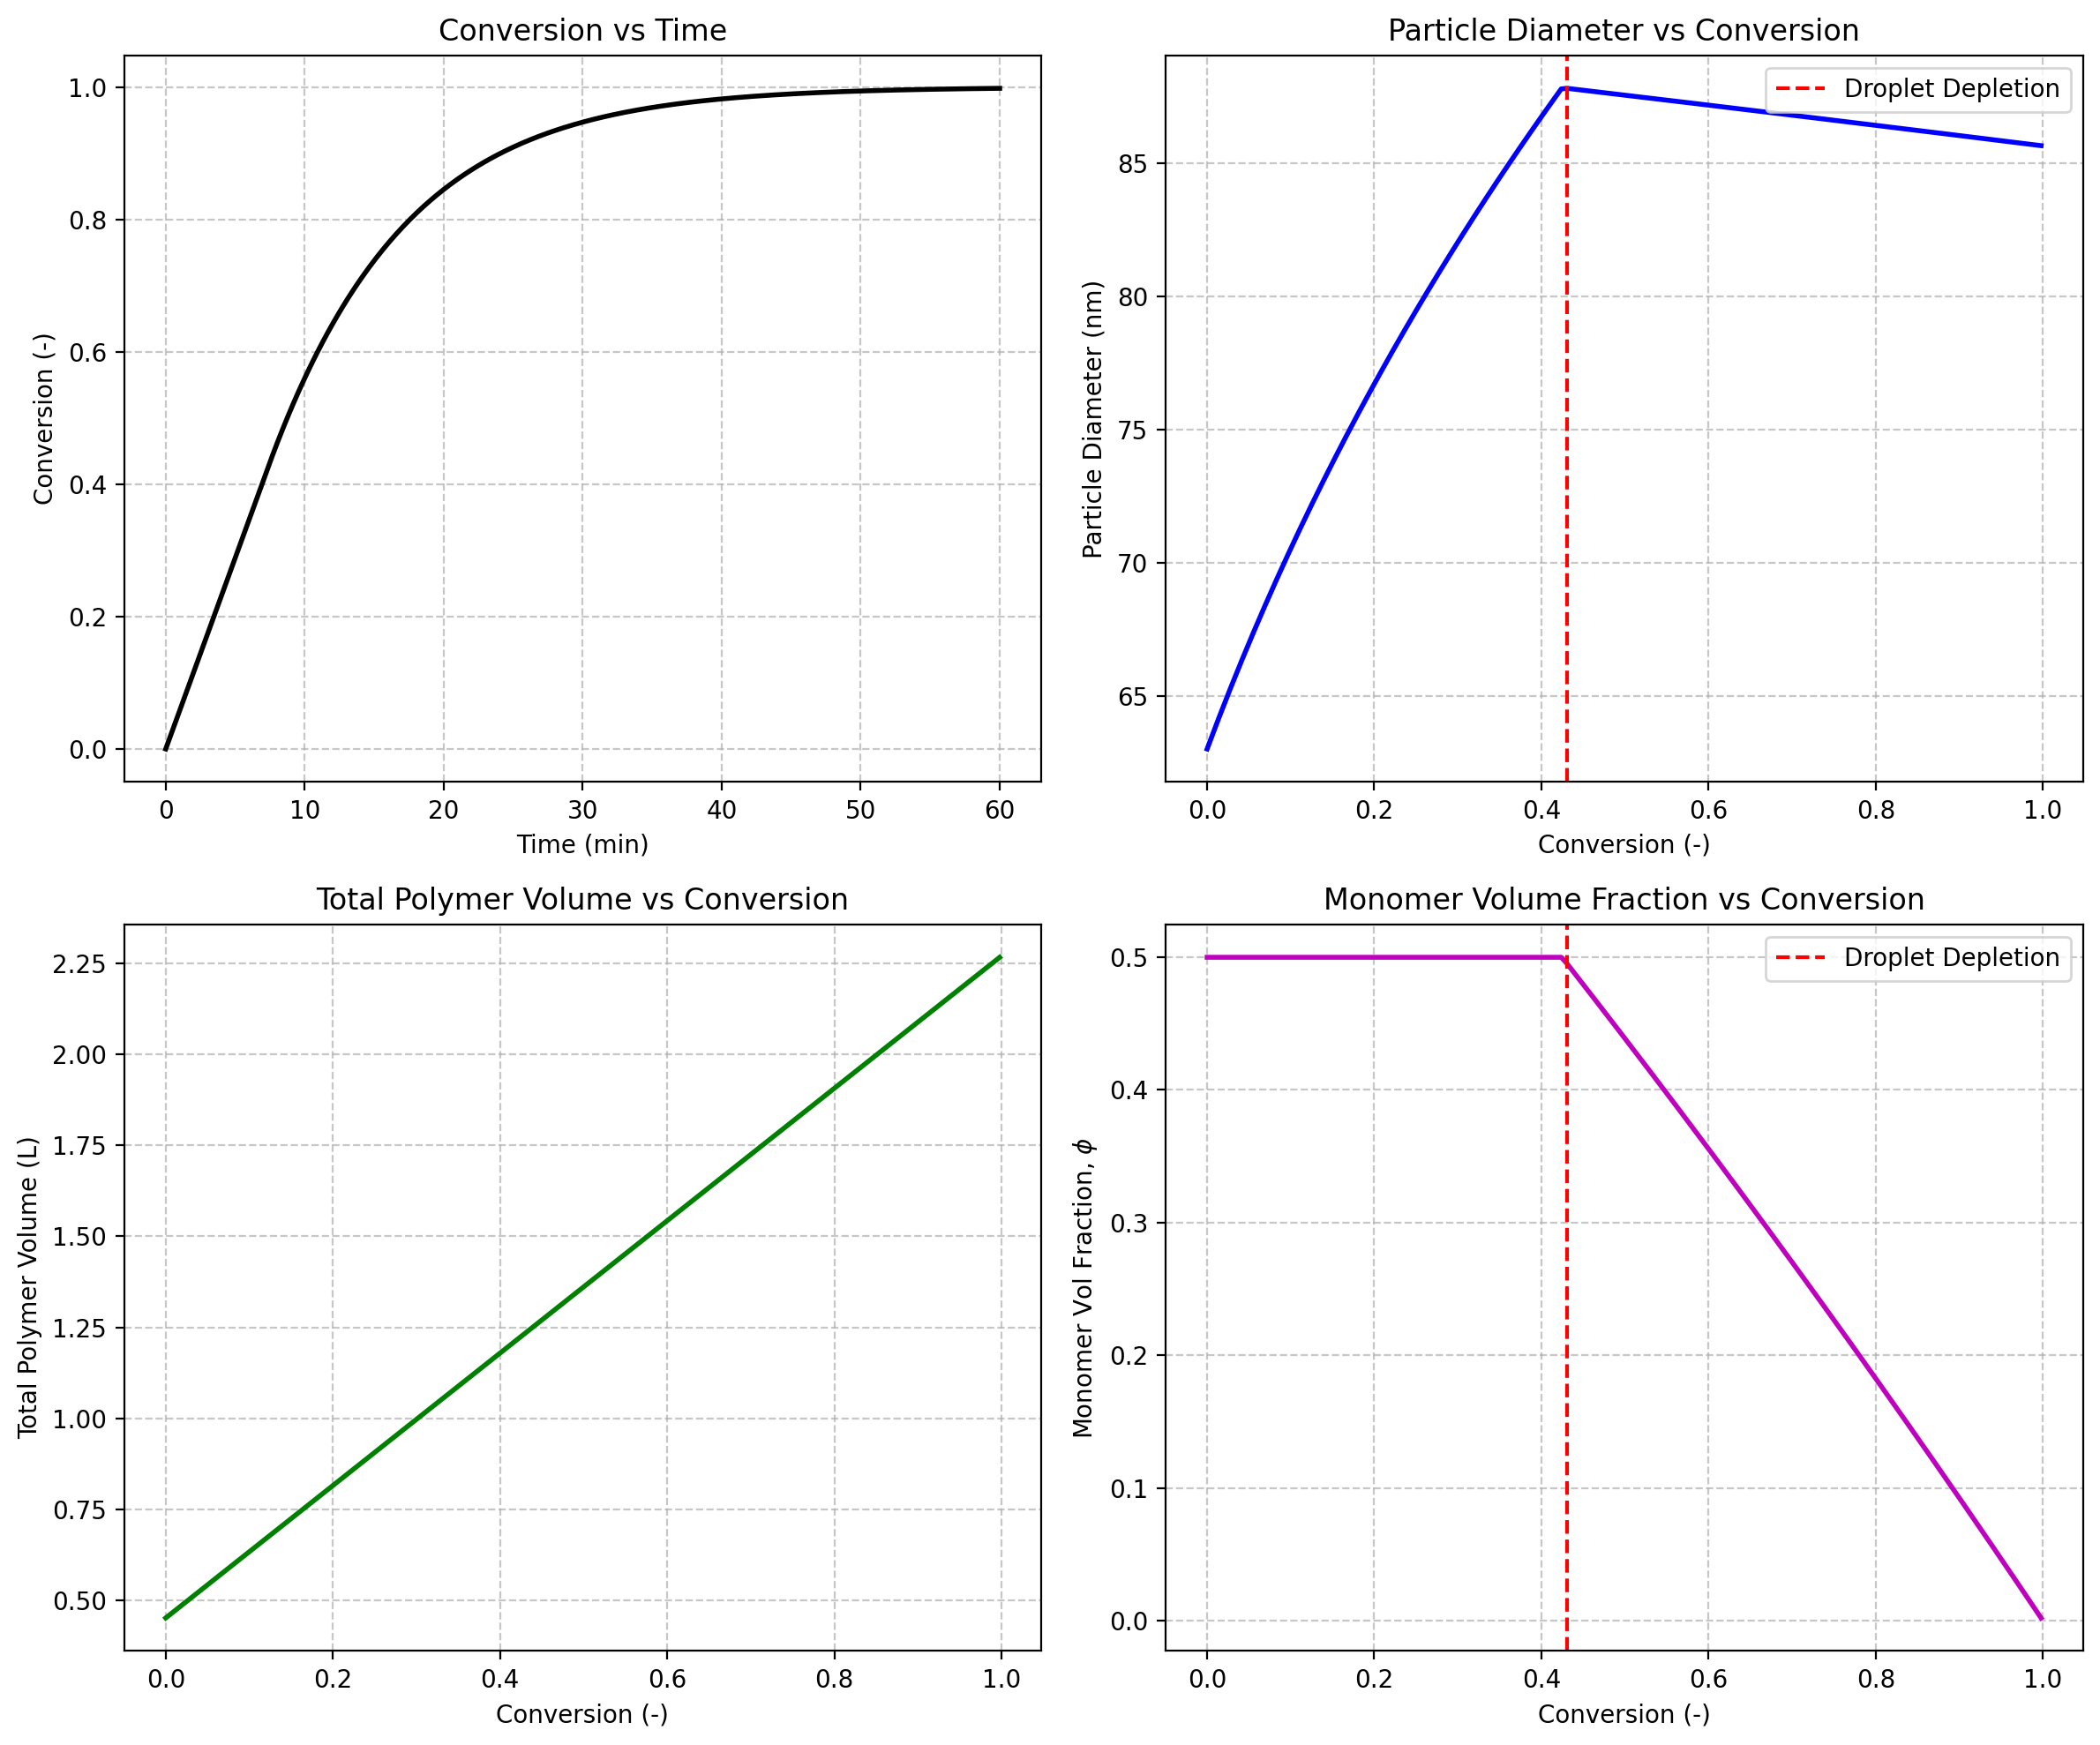

In [ ]:
v_pol_0 = m_pol / (N_p * rho_pol)      # Initial polymer volume per particle (L)

# Q2: Volumetric Kinetics Simulation

def volumetric_kinetics(t, Y):
    v_pol = Y[0]
    v_mon_avail_per_particle = (m_M / N_p - (v_pol - v_pol_0) * rho_pol) / rho_M
    
    # Check Interval (Droplets present vs. depleted)
    phi = phi_M_star if v_mon_avail_per_particle > v_pol else (v_mon_avail_per_particle / (v_mon_avail_per_particle + v_pol))
        
    # Integrate Eq 2.14: Volumetric growth of polymer in a single particle
    dv_pol_dt = kp * phi * (0.5 / N_A) * (rho_M / rho_pol)
    return [dv_pol_dt]

# Integrate ODE with max_step to smoothly cross the interval transition
t_span = (0, 3600)  # 1 hour
sol = solve_ivp(volumetric_kinetics, t_span, [v_pol_0], t_eval=np.linspace(0, 3600, 500), max_step=5.0)

time = sol.t
v_pol_arr = sol.y[0]

# Derived Variables

# Global conversion and total volume
conversion = np.clip((N_p * (v_pol_arr - v_pol_0) * rho_pol) / m_M, 0.0, 1.0)
V_pol_total_arr = v_pol_arr * N_p

# Vectorized monomer availability
v_mon_avail_arr = np.maximum(0.0, (m_M / N_p - (v_pol_arr - v_pol_0) * rho_pol) / rho_M)

# Boolean mask to identify Interval II
interval_II = v_mon_avail_arr > v_pol_arr

# Vectorized calculations using np.where(condition, true_value, false_value)
phi_arr = np.where(interval_II, phi_M_star, v_mon_avail_arr / (v_mon_avail_arr + v_pol_arr))
v_p_tot_arr = np.where(interval_II, v_pol_arr / (1 - phi_M_star), v_pol_arr + v_mon_avail_arr)

# Vectorized Diameter calculation
diam_arr = ((6 * v_p_tot_arr) / np.pi)**(1/3) * 1e8  # dm to nm

# Exact depletion point
depletion_idx = np.argmax(~interval_II) # Finds the first index where interval_II is False
X_depletion = conversion[depletion_idx] if depletion_idx > 0 else 0


# --- Plotting ---
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

axs[0,0].plot(time / 60, conversion, 'k-', linewidth=2)
axs[0,0].set_xlabel('Time (min)')
axs[0,0].set_ylabel('Conversion (-)')
axs[0,0].set_title('Conversion vs Time')
axs[0,0].grid(True, linestyle='--', alpha=0.7)

axs[0,1].plot(conversion, diam_arr, 'b-', linewidth=2)
if depletion_idx != -1:
    axs[0,1].axvline(X_depletion, color='r', linestyle='--', label='Droplet Depletion')
axs[0,1].set_xlabel('Conversion (-)')
axs[0,1].set_ylabel('Particle Diameter (nm)')
axs[0,1].set_title('Particle Diameter vs Conversion')
axs[0,1].legend()
axs[0,1].grid(True, linestyle='--', alpha=0.7)

axs[1,0].plot(conversion, V_pol_total_arr, 'g-', linewidth=2)
axs[1,0].set_xlabel('Conversion (-)')
axs[1,0].set_ylabel('Total Polymer Volume (L)')
axs[1,0].set_title('Total Polymer Volume vs Conversion')
axs[1,0].grid(True, linestyle='--', alpha=0.7)

axs[1,1].plot(conversion, phi_arr, 'm-', linewidth=2)
if depletion_idx != -1:
    axs[1,1].axvline(X_depletion, color='r', linestyle='--', label='Droplet Depletion')
axs[1,1].set_xlabel('Conversion (-)')
axs[1,1].set_ylabel('Monomer Vol Fraction, $\\phi$')
axs[1,1].set_title('Monomer Volume Fraction vs Conversion')
axs[1,1].legend()
axs[1,1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

The plots illustrate the two distinct kinetic regimes dictated by Smith-Ewart kinetics. In Interval II, the monomer volume fraction $\phi$ remains constant at $0.5$ due to monomer droplet partitioning, leading to linear growth in particle diameter and a constant reaction rate (linear conversion over time). Once droplets deplete, we enter Interval III: the conversion rate progressively drops, $\phi$ decays toward zero, and the particle diameter slightly contracts as low-density monomer converts into higher-density polymer.